# Defect Segmentation + Measurement for a Hanging Metal Plate

A **supervised** alternative to the PatchCore notebook. Instead of asking "does this image look unusual?", we teach a small segmentation network to **paint the defective pixels**, then derive the verdict and the defect size from that painted region.

## Pipeline

| # | Step | What happens |
|---|------|--------------|
| 1 | **Background removal** | `rembg` (U-2-Net) or classical GrabCut isolates the metal plate -> *object mask* |
| 2 | **Crop & resize** | The image is cropped to the plate's bounding box and resized to a fixed size, with the background blanked out |
| 3 | **Segmentation model** | A U-Net with a pretrained ResNet18 encoder predicts, for every pixel *inside the plate*, "good" or "NG" (defect) |
| 4 | **Back to full resolution** | The prediction is pasted back into the original frame, thresholded, and cleaned of tiny specks |
| 5 | **Decision** | `NG % = NG area / plate area * 100`. If it exceeds a cut-off the plate is **NG**, otherwise **OK** |
| 6 | **Defect dimensions** | Each connected NG region is measured: area, length, width, max diameter (px, and mm if calibrated) |

## Training labels

* **Good image:** the whole plate is "good" -> target = all zeros inside the plate (the plate mask from step 1 defines "inside").
* **Bad image:** your defect mask marks the NG pixels; everything else inside the plate is "good".
* The loss is computed **only inside the plate**, so the network never has to learn about the background.

## Folder layout (new folder, so it won't clash with the PatchCore data)

```
data/seg/
├── train/
│   ├── good/         <- images with no defect
│   ├── bad/          <- images with defects
│   └── bad_masks/    <- defect masks, SAME file name as in bad/ (png; white = defect). "_mask" suffix also accepted
└── test/
    ├── good/
    ├── bad/
    └── bad_masks/    <- optional for test, but needed for pixel-level scores and dimension checks
```

Notes
* Images and masks must show the same view (same orientation and aspect ratio). Mask files may be 0/255 or 0/1.
* A random 20 % of the *train* folder is held out for validation (stratified). The *test* folder is only used at the end.
* This notebook is **self-contained**: it does not import from `src/` or `scripts/`.
* A supervised model finds defect types it has *seen*. A brand-new kind of defect may be missed. The PatchCore notebook has the opposite strength, so the two are complementary.

In [ ]:
# Run once if packages are missing (torch / torchvision / scikit-learn / matplotlib come from requirements.txt):
# %pip install opencv-python-headless pandas "rembg[cpu]"
#
# rembg downloads its U-2-Net model (~170 MB; "u2netp" is ~5 MB) the first time it runs, so it needs internet once.
# If rembg won't install or you are offline, set CFG.bg_method = "grabcut" below (classical OpenCV, no download).

## 1. Imports and settings

In [3]:
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # must be set BEFORE torch is imported (Apple GPU fallback)

import hashlib, math, random, time
from pathlib import Path
from types import SimpleNamespace

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from IPython.display import display
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

CFG = SimpleNamespace(
    # ---- paths ----
    data_root=ROOT / "data" / "seg",
    out_dir=ROOT / "outputs" / "segmentation",
    model_path=ROOT / "models" / "seg_unet.pt",

    # ---- step 1: background removal ----
    bg_method="rembg",        # "rembg" (U-2-Net, best quality) | "grabcut" (classical OpenCV, no download)
    rembg_model="u2net",      # u2net | u2netp (smaller/faster) | isnet-general-use | silueta
    grabcut_margin=0.05,      # grabcut only: plate assumed to lie inside the frame, this fraction away from the borders
    max_side=2048,            # images larger than this (long side, px) are downscaled for speed/memory
    mask_open_px=0,           # >0 removes thin attachments (hook / chain / rope): morphological opening kernel size in px
    fill_holes=False,         # True fills holes inside the plate mask (use if the mask has spurious holes)
    force_recompute_bg=False, # True ignores the cached background masks

    # ---- model input ----
    input_size=(384, 384),    # (height, width) fed to the network, multiples of 32. Raise for tiny defects, or use e.g. (256, 640) for long plates
    crop_margin=0.03,         # extra border around the plate's bounding box (fraction of its longer side)

    # ---- training ----
    val_fraction=0.2,         # share of the train folder held out for validation
    batch_size=4,             # 4 is safe on 8 GB RAM
    epochs=30,
    samples_per_epoch=160,    # images drawn per epoch (bad images are over-sampled, see bad_fraction)
    bad_fraction=0.5,         # share of each epoch's samples that come from bad images
    lr_encoder=1e-4,          # pretrained ResNet part
    lr_decoder=1e-3,          # freshly initialised part
    aug_flip=True,            # random horizontal/vertical flips
    aug_rotate=10,            # +- degrees
    aug_scale=0.10,           # +- fraction
    aug_shift=0.05,           # +- fraction of the image size
    aug_contrast=0.20,        # +- fraction
    aug_brightness=20,        # +- grey levels (0-255)

    # ---- inference / decision ----
    pixel_thr=0.5,            # probability above which a pixel is called NG
    min_defect_frac=0.0002,   # NG blobs smaller than this fraction of the plate area are discarded as noise
    ng_percent_thr=0.5,       # plate is NG if NG area >= this % of the plate area (tuned in section 9)

    # ---- real-world units (leave both None to report pixels only) ----
    mm_per_pixel=None,        # e.g. 0.12 = millimetres per pixel of the ORIGINAL image (fixed camera setup)
    plate_long_side_mm=None,  # alternative: known real length of the plate's longer side, scale is derived per image

    seed=0,
    device="auto",            # auto | mps | cuda | cpu
)
CFG.cache_dir = CFG.out_dir / "cache"

def get_device(name="auto"):
    if name != "auto":
        return torch.device(name)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

DEVICE = get_device(CFG.device)
seed_everything(CFG.seed)
print("project root:", ROOT)
print("data root   :", CFG.data_root)
print("device      :", DEVICE)

/Users/sarathchintalapati/Desktop/TakeHomeAssisment/anomaly-detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


project root: /Users/sarathchintalapati/Desktop/TakeHomeAssisment/anomaly-detection
data root   : /Users/sarathchintalapati/Desktop/TakeHomeAssisment/anomaly-detection/data/seg
device      : mps


## 2. Step 1: Background removal

`remove_background` returns a rough mask. `clean_object_mask` then keeps only the **largest connected region** (the plate), optionally trims thin hooks/chains and fills holes.
Masks are cached on disk (`outputs/segmentation/cache`), so the slow background model runs only once per image.

In [4]:
IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}

def list_images(folder):
    folder = Path(folder)
    if not folder.exists():
        return []
    return sorted(p for p in folder.rglob("*") if p.suffix.lower() in IMG_EXTS and not p.name.startswith("."))

def load_rgb(path):
    # returns (uint8 RGB array, scale). scale >= 1 is the factor by which the image was shrunk to respect max_side
    img = Image.open(path).convert("RGB")
    w0, h0 = img.size
    scale = max(1.0, max(w0, h0) / CFG.max_side)
    if scale > 1.0:
        img = img.resize((round(w0 / scale), round(h0 / scale)), Image.LANCZOS)
    return np.array(img), scale

def load_binary_mask(path, shape):
    # reads a defect mask (0/255 or 0/1, any image format) and returns a uint8 0/1 array of the given (H, W)
    m = np.array(Image.open(path).convert("L"))
    if m.shape != tuple(shape):
        m = cv2.resize(m, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)
    thr = 0 if m.max() <= 1 else 127
    return (m > thr).astype(np.uint8)

# ---------- background removal back-ends ----------
_REMBG_SESSION = None

def _remove_bg_rembg(img):
    global _REMBG_SESSION
    try:
        from rembg import remove, new_session
    except ImportError as e:
        raise ImportError('rembg is not installed. Run:  %pip install "rembg[cpu]"   (or set CFG.bg_method = "grabcut")') from e
    if _REMBG_SESSION is None:
        _REMBG_SESSION = new_session(CFG.rembg_model)
    return np.array(remove(Image.fromarray(img), session=_REMBG_SESSION, only_mask=True))   # uint8, 0..255

def _remove_bg_grabcut(img):
    h, w = img.shape[:2]
    s = 640.0 / max(h, w)
    small = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA) if s < 1 else img
    sh, sw = small.shape[:2]
    mx, my = int(sw * CFG.grabcut_margin), int(sh * CFG.grabcut_margin)
    rect = (mx, my, sw - 2 * mx, sh - 2 * my)
    mask = np.zeros((sh, sw), np.uint8)
    bgd, fgd = np.zeros((1, 65), np.float64), np.zeros((1, 65), np.float64)
    cv2.grabCut(cv2.cvtColor(small, cv2.COLOR_RGB2BGR), mask, rect, bgd, fgd, 5, cv2.GC_INIT_WITH_RECT)
    fg = np.where((mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD), 255, 0).astype(np.uint8)
    return cv2.resize(fg, (w, h), interpolation=cv2.INTER_NEAREST) if s < 1 else fg

def clean_object_mask(raw):
    m = (raw > 127).astype(np.uint8)
    if CFG.mask_open_px > 0:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (CFG.mask_open_px, CFG.mask_open_px))
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, k)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    if n > 1:                                                   # keep only the largest region = the plate
        keep = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
        m = (lab == keep).astype(np.uint8)
    if CFG.fill_holes:
        cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        filled = np.zeros_like(m)
        cv2.drawContours(filled, cnts, -1, 1, thickness=-1)
        m = filled
    return m

def get_object_mask(img_path, img):
    # plate mask (uint8 0/1, same H x W as img). The raw background-removal output is cached on disk.
    tag = hashlib.md5(str(Path(img_path).resolve()).encode()).hexdigest()[:8]
    model_tag = CFG.rembg_model if CFG.bg_method == "rembg" else "gc"
    f = CFG.cache_dir / f"{Path(img_path).stem}_{tag}_{CFG.bg_method}_{model_tag}_{CFG.max_side}.png"
    raw = None
    if f.exists() and not CFG.force_recompute_bg:
        raw = np.array(Image.open(f))
        if raw.shape != img.shape[:2]:
            raw = None
    if raw is None:
        raw = _remove_bg_rembg(img) if CFG.bg_method == "rembg" else _remove_bg_grabcut(img)
        f.parent.mkdir(parents=True, exist_ok=True)
        Image.fromarray(raw).save(f)
    return clean_object_mask(raw)

### Sanity check: is the plate cut out correctly?

Look at these before training. If the outline includes the hook or leaves parts of the plate out, adjust `bg_method`, `rembg_model`, `mask_open_px` or `fill_holes` in the settings, set `force_recompute_bg=True` once, and rerun.

train: 54 good, 58 bad (with mask)


100%|████████████████████████████████████████| 176M/176M [00:00<00:00, 253GB/s]


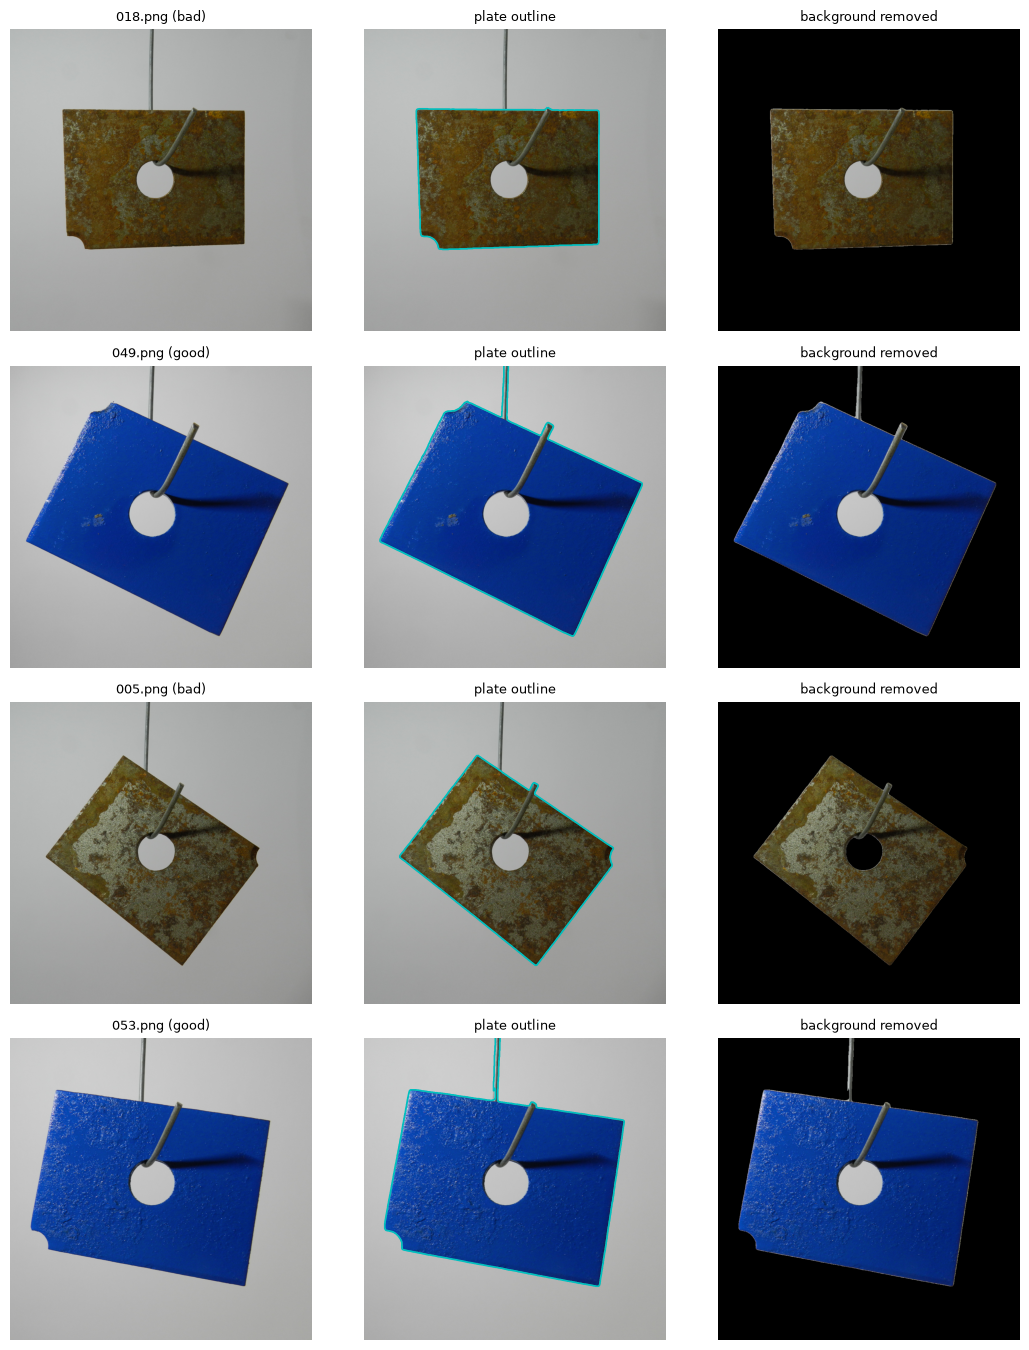

In [6]:
def collect_items(split, require_mask=True):
    # returns a list of (image_path, label, mask_path). label 0 = good, 1 = bad
    root = CFG.data_root / split
    items = [(p, 0, None) for p in list_images(root / "good")]
    lookup = {p.stem: p for p in list_images(root / "bad_masks")}
    for p in list_images(root / "bad"):
        mp = lookup.get(p.stem) or lookup.get(p.stem + "_mask") or lookup.get(p.stem + "_gt")
        if mp is None and require_mask:
            print(f"[warn] no mask found for {p.name} -> skipped")
            continue
        items.append((p, 1, mp))
    return items

def show_bg_removal(items, n=4):
    items = random.Random(CFG.seed).sample(items, min(n, len(items)))
    fig, axes = plt.subplots(len(items), 3, figsize=(11, 3.4 * len(items)), squeeze=False)
    for row, (p, label, _) in zip(axes, items):
        img, _ = load_rgb(p)
        obj = get_object_mask(p, img)
        row[0].imshow(img); row[0].set_title(f"{p.name} ({'bad' if label else 'good'})", fontsize=9)
        row[1].imshow(img)
        for c in cv2.findContours(obj, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]:
            c = c[:, 0, :]; row[1].plot(c[:, 0], c[:, 1], "c-", lw=1.2)
        row[1].set_title("plate outline", fontsize=9)
        row[2].imshow(img * obj[..., None]); row[2].set_title("background removed", fontsize=9)
        for a in row: a.axis("off")
    plt.tight_layout(); plt.show()

train_items_all = collect_items("train", require_mask=True)
print(f"train: {sum(1 for i in train_items_all if i[1] == 0)} good, {sum(1 for i in train_items_all if i[1] == 1)} bad (with mask)")
assert train_items_all, f"No training images found under {CFG.data_root / 'train'}. See the folder layout at the top."
show_bg_removal(train_items_all, n=4)

## 3. Build the training data

For every image: remove the background, **crop to the plate's bounding box**, and resize to `input_size`. Doing this once up front keeps training fast.
For bad images the plate mask is merged with the defect mask, so a defect such as a chipped edge is never cut off by the background step.

In [7]:
def object_bbox(obj, margin):
    ys, xs = np.nonzero(obj)
    if len(xs) == 0:
        raise ValueError("empty plate mask (background removal found nothing)")
    x0, x1, y0, y1 = xs.min(), xs.max() + 1, ys.min(), ys.max() + 1
    pad = int(margin * max(x1 - x0, y1 - y0))
    H, W = obj.shape
    return int(max(0, x0 - pad)), int(max(0, y0 - pad)), int(min(W, x1 + pad)), int(min(H, y1 + pad))

def resize_to(a, size, mask=False):
    # size = (H, W). Binary masks use nearest-neighbour; images use area/linear interpolation.
    h, w = size
    if mask:
        return cv2.resize(a, (w, h), interpolation=cv2.INTER_NEAREST)
    interp = cv2.INTER_AREA if a.shape[0] * a.shape[1] > h * w else cv2.INTER_LINEAR
    return cv2.resize(a, (w, h), interpolation=interp)

def make_crop(img, obj):
    x0, y0, x1, y1 = object_bbox(obj, CFG.crop_margin)
    ci = resize_to(img[y0:y1, x0:x1], CFG.input_size)
    co = resize_to(np.ascontiguousarray(obj[y0:y1, x0:x1]), CFG.input_size, mask=True)
    return ci, co, (x0, y0, x1, y1)

def build_record(img_path, label, mask_path):
    img, scale = load_rgb(img_path)
    obj = get_object_mask(img_path, img)
    gt = load_binary_mask(mask_path, img.shape[:2]) if mask_path is not None else np.zeros(img.shape[:2], np.uint8)
    if label == 1:
        obj = np.maximum(obj, gt)                      # defect pixels always count as "inside the plate"
    ci, co, (x0, y0, x1, y1) = make_crop(img, obj)
    cg = resize_to(np.ascontiguousarray(gt[y0:y1, x0:x1]), CFG.input_size, mask=True)
    return dict(path=str(img_path), label=label, image=ci, obj=co, mask=cg, scale=scale)

def build_records(items, desc):
    recs = []
    for p, label, mp in tqdm(items, desc=desc):
        try:
            recs.append(build_record(p, label, mp))
        except Exception as e:
            print(f"[warn] skipped {Path(p).name}: {e}")
    return recs

def stratified_split(items, frac, seed):
    rng = np.random.RandomState(seed)
    tr, va = [], []
    for lab in (0, 1):
        g = [it for it in items if it[1] == lab]
        idx = rng.permutation(len(g))
        n_val = int(round(len(g) * frac))
        if lab == 1 and len(g) >= 2:
            n_val = max(1, n_val)                      # always keep at least one bad image for validation
        va += [g[i] for i in idx[:n_val]]
        tr += [g[i] for i in idx[n_val:]]
    return tr, va

train_items, val_items = stratified_split(train_items_all, CFG.val_fraction, CFG.seed)
print(f"train: {len(train_items)} images | validation: {len(val_items)} images")

t0 = time.time()
train_recs = build_records(train_items, "preparing train")
val_recs = build_records(val_items, "preparing val")
print(f"done in {time.time() - t0:.0f}s | bad images: train {sum(r['label'] for r in train_recs)}, val {sum(r['label'] for r in val_recs)}")

train: 89 images | validation: 23 images


preparing val: 100%|██████████| 23/23 [00:07<00:00,  2.98it/s]

done in 37s | bad images: train 46, val 12


### Augmentation and dataset

With only a few defect images, augmentation matters a lot. Geometry changes (flip, small rotation, scale, shift) are applied identically to the image, the plate mask and the defect mask; brightness/contrast changes only touch the image.

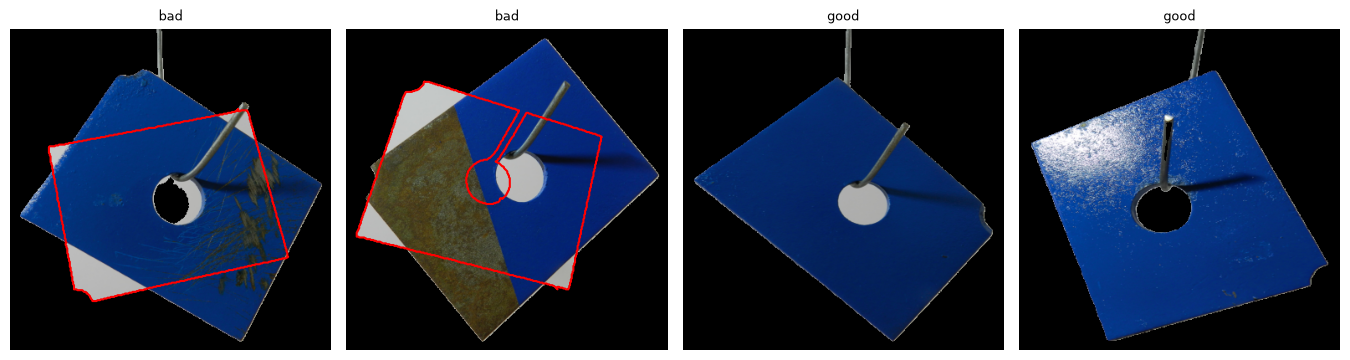

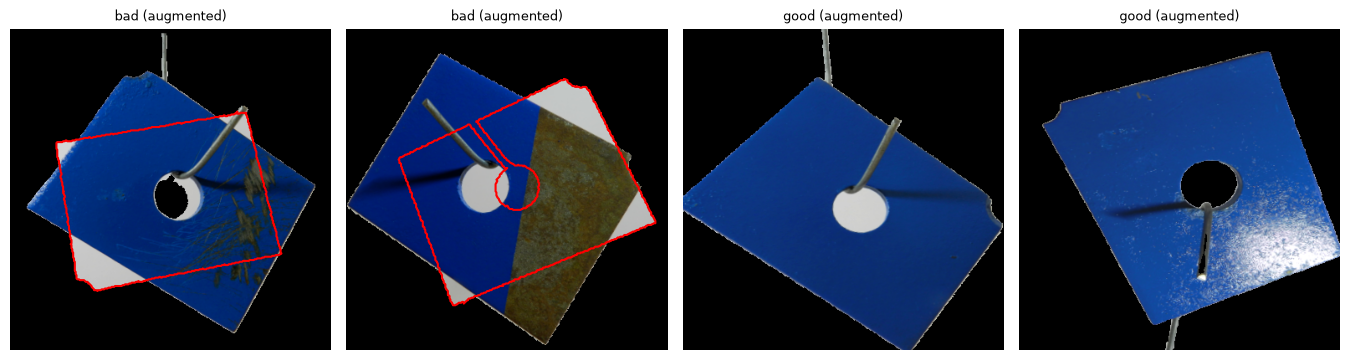

In [8]:
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)

def augment(img, obj, msk):
    if CFG.aug_flip:
        if random.random() < 0.5:
            img, obj, msk = img[:, ::-1], obj[:, ::-1], msk[:, ::-1]
        if random.random() < 0.5:
            img, obj, msk = img[::-1], obj[::-1], msk[::-1]
    h, w = obj.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), random.uniform(-CFG.aug_rotate, CFG.aug_rotate),
                                random.uniform(1 - CFG.aug_scale, 1 + CFG.aug_scale))
    M[0, 2] += random.uniform(-CFG.aug_shift, CFG.aug_shift) * w
    M[1, 2] += random.uniform(-CFG.aug_shift, CFG.aug_shift) * h
    img = cv2.warpAffine(np.ascontiguousarray(img), M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    obj = cv2.warpAffine(np.ascontiguousarray(obj), M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    msk = cv2.warpAffine(np.ascontiguousarray(msk), M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    a = random.uniform(1 - CFG.aug_contrast, 1 + CFG.aug_contrast)
    b = random.uniform(-CFG.aug_brightness, CFG.aug_brightness)
    img = np.clip(img.astype(np.float32) * a + b, 0, 255).astype(np.uint8)
    return img, obj, msk * obj

def to_input(img, obj):
    # normalise, then blank the background (0 = mean colour after normalisation) -> array of shape (3, H, W)
    x = (img.astype(np.float32) / 255.0 - MEAN) / STD
    x = x * obj[..., None].astype(np.float32)
    return np.ascontiguousarray(x.transpose(2, 0, 1))

def show_records(recs, n=4, augmented=False):
    # visual check that images, plate masks and defect masks line up
    picks = [r for r in recs if r["label"] == 1][: n // 2 + n % 2] + [r for r in recs if r["label"] == 0][: n // 2]
    fig, axes = plt.subplots(1, len(picks), figsize=(3.4 * len(picks), 3.6), squeeze=False)
    for ax, r in zip(axes[0], picks):
        img, obj, msk = (augment(r["image"], r["obj"], r["mask"]) if augmented else (r["image"], r["obj"], r["mask"]))
        ax.imshow(img * obj[..., None])
        for c in cv2.findContours(np.ascontiguousarray(msk), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]:
            c = c[:, 0, :]; ax.plot(np.r_[c[:, 0], c[0, 0]], np.r_[c[:, 1], c[0, 1]], "r-", lw=1.5)
        ax.set_title(("bad" if r["label"] else "good") + (" (augmented)" if augmented else ""), fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()

show_records(train_recs, 4)                    # red outline = defect mask you provided
show_records(train_recs, 4, augmented=True)    # same, after random augmentation

In [9]:
class SegDataset(Dataset):
    def __init__(self, recs, train):
        self.recs, self.train = recs, train
    def __len__(self):
        return len(self.recs)
    def __getitem__(self, i):
        r = self.recs[i]
        img, obj, msk = r["image"], r["obj"], r["mask"]
        if self.train:
            img, obj, msk = augment(img, obj, msk)
        x = torch.from_numpy(to_input(img, obj))
        y = torch.from_numpy(msk.astype(np.float32))[None]       # 1 = NG pixel
        m = torch.from_numpy(obj.astype(np.float32))[None]       # 1 = inside the plate (the loss only looks here)
        return x, y, m

## 4. Model: a small U-Net with a pretrained ResNet18 encoder

* The **encoder** is ResNet18 pretrained on ImageNet (so it already understands edges and textures). With so few defect images, this is what makes training feasible.
* The **decoder** upsamples step by step and merges in early, high-resolution features through skip connections, which gives sharp defect outlines.
* The output is one logit per pixel; `sigmoid` turns it into the probability that the pixel is NG.
* Loss = binary cross-entropy + Dice, both computed **only inside the plate**. Dice copes with defects being a tiny share of the pixels.

In [10]:
class ConvBlock(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class ResNetUNet(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        net = torchvision.models.get_model("resnet18", weights="DEFAULT" if pretrained else None)
        self.enc0 = nn.Sequential(net.conv1, net.bn1, net.relu)      # 1/2 resolution,  64 ch
        self.pool = net.maxpool
        self.enc1, self.enc2, self.enc3, self.enc4 = net.layer1, net.layer2, net.layer3, net.layer4   # 1/4, 1/8, 1/16, 1/32
        self.dec4 = ConvBlock(512 + 256, 256)
        self.dec3 = ConvBlock(256 + 128, 128)
        self.dec2 = ConvBlock(128 + 64, 64)
        self.dec1 = ConvBlock(64 + 64, 32)
        self.head = nn.Conv2d(32, 1, 1)

    def encoder_parameters(self):
        return [p for m in (self.enc0, self.enc1, self.enc2, self.enc3, self.enc4) for p in m.parameters()]

    def decoder_parameters(self):
        return [p for m in (self.dec4, self.dec3, self.dec2, self.dec1, self.head) for p in m.parameters()]

    @staticmethod
    def _up(x, ref):
        return F.interpolate(x, size=ref.shape[-2:], mode="bilinear", align_corners=False)

    def forward(self, x):
        size = x.shape[-2:]
        x0 = self.enc0(x)
        x1 = self.enc1(self.pool(x0))
        x2 = self.enc2(x1)
        x3 = self.enc3(x2)
        x4 = self.enc4(x3)
        d = self.dec4(torch.cat([self._up(x4, x3), x3], 1))
        d = self.dec3(torch.cat([self._up(d, x2), x2], 1))
        d = self.dec2(torch.cat([self._up(d, x1), x1], 1))
        d = self.dec1(torch.cat([self._up(d, x0), x0], 1))
        return F.interpolate(self.head(d), size=size, mode="bilinear", align_corners=False)    # logits, (B, 1, H, W)


def masked_bce_dice(logits, target, valid, eps=1.0):
    # BCE + soft Dice, counting only pixels where valid == 1 (inside the plate)
    bce = F.binary_cross_entropy_with_logits(logits, target, reduction="none")
    bce = (bce * valid).sum() / valid.sum().clamp(min=1.0)
    p, t = torch.sigmoid(logits) * valid, target * valid
    dice = 1.0 - (2.0 * (p * t).sum() + eps) / (p.sum() + t.sum() + eps)
    return bce + dice


@torch.no_grad()
def eval_epoch(model, loader):
    # returns (mean loss, pooled Dice). Pooled Dice also punishes false alarms on good images.
    model.eval()
    tot, n, inter, ps, gs = 0.0, 0, 0.0, 0.0, 0.0
    for x, y, m in loader:
        x, y, m = x.to(DEVICE), y.to(DEVICE), m.to(DEVICE)
        logits = model(x)
        tot += masked_bce_dice(logits, y, m).item() * x.shape[0]; n += x.shape[0]
        pred = (torch.sigmoid(logits) >= CFG.pixel_thr).float() * m
        inter += (pred * y).sum().item(); ps += pred.sum().item(); gs += y.sum().item()
    dice = 2 * inter / (ps + gs) if (ps + gs) > 0 else float("nan")
    return tot / max(n, 1), dice


def load_model(path):
    ck = torch.load(path, map_location="cpu")
    CFG.input_size, CFG.crop_margin = tuple(ck["input_size"]), float(ck["crop_margin"])   # must match what the model was trained with
    model = ResNetUNet(pretrained=False)
    model.load_state_dict(ck["state_dict"])
    print(f"loaded {path} (epoch {ck['epoch']}, val Dice {ck['val_dice']:.3f}, input_size {CFG.input_size})")
    return model.to(DEVICE).eval()

## 5. Train

Each epoch draws `samples_per_epoch` images, with about half of them taken from the (few) bad images so the network sees plenty of defects.
The best model, judged by validation Dice, is saved to `models/seg_unet.pt`. You can interrupt the cell (stop button) at any time. The best model so far is kept.

Expect roughly 1-3 minutes per epoch on CPU, much less on Apple GPU (MPS). Lower `input_size` or `epochs` for a quick first try.

In [11]:
labels = np.array([r["label"] for r in train_recs])
n_bad, n_good = int(labels.sum()), int((labels == 0).sum())
assert n_bad > 0, "No bad training images with masks found. Check data/seg/train/bad and bad_masks."
weights = np.where(labels == 1, CFG.bad_fraction / n_bad, (1 - CFG.bad_fraction) / max(n_good, 1))
sampler = WeightedRandomSampler(torch.as_tensor(weights, dtype=torch.double), num_samples=CFG.samples_per_epoch, replacement=True)

train_loader = DataLoader(SegDataset(train_recs, train=True), batch_size=CFG.batch_size, sampler=sampler, num_workers=0, drop_last=True)
val_loader = DataLoader(SegDataset(val_recs, train=False), batch_size=CFG.batch_size, shuffle=False, num_workers=0)

MODEL = ResNetUNet(pretrained=True).to(DEVICE)
opt = torch.optim.AdamW([{"params": MODEL.encoder_parameters(), "lr": CFG.lr_encoder},
                         {"params": MODEL.decoder_parameters(), "lr": CFG.lr_decoder}], weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG.epochs)

CFG.model_path.parent.mkdir(parents=True, exist_ok=True)
history, best = [], -1e9
try:
    for epoch in range(1, CFG.epochs + 1):
        t0 = time.time()
        MODEL.train()
        run, nb = 0.0, 0
        for x, y, m in train_loader:
            x, y, m = x.to(DEVICE), y.to(DEVICE), m.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss = masked_bce_dice(MODEL(x), y, m)
            loss.backward()
            opt.step()
            run += loss.item(); nb += 1
        sched.step()
        val_loss, val_dice = eval_epoch(MODEL, val_loader)
        score = val_dice if not math.isnan(val_dice) else -val_loss
        saved = ""
        if score > best:
            best = score
            torch.save({"state_dict": MODEL.state_dict(), "input_size": list(CFG.input_size), "crop_margin": CFG.crop_margin,
                        "epoch": epoch, "val_dice": float(val_dice)}, CFG.model_path)
            saved = "  <- saved"
        history.append(dict(epoch=epoch, train_loss=run / max(nb, 1), val_loss=val_loss, val_dice=val_dice))
        print(f"epoch {epoch:02d}/{CFG.epochs} | train loss {run / max(nb, 1):.4f} | val loss {val_loss:.4f} | "
              f"val Dice {val_dice:.3f} | {time.time() - t0:.0f}s{saved}")
except KeyboardInterrupt:
    print("training interrupted, keeping the best model saved so far")

MODEL = load_model(CFG.model_path)

epoch 01/30 | train loss 0.9629 | val loss 0.9399 | val Dice 0.782 | 10s  <- saved
epoch 02/30 | train loss 0.8529 | val loss 0.9216 | val Dice 0.751 | 5s
epoch 03/30 | train loss 0.6742 | val loss 0.8739 | val Dice 0.788 | 5s  <- saved
epoch 04/30 | train loss 0.6010 | val loss 0.7764 | val Dice 0.833 | 5s  <- saved
epoch 05/30 | train loss 0.5011 | val loss 0.7732 | val Dice 0.820 | 5s
epoch 06/30 | train loss 0.5060 | val loss 0.8577 | val Dice 0.821 | 5s
epoch 07/30 | train loss 0.5079 | val loss 0.7991 | val Dice 0.788 | 5s
epoch 08/30 | train loss 0.4276 | val loss 0.8470 | val Dice 0.789 | 5s
epoch 09/30 | train loss 0.4055 | val loss 0.8113 | val Dice 0.797 | 5s
epoch 10/30 | train loss 0.3806 | val loss 0.8146 | val Dice 0.830 | 5s
epoch 11/30 | train loss 0.4315 | val loss 0.7467 | val Dice 0.807 | 5s
epoch 12/30 | train loss 0.2945 | val loss 0.6505 | val Dice 0.869 | 5s  <- saved
epoch 13/30 | train loss 0.3804 | val loss 0.6862 | val Dice 0.856 | 5s
epoch 14/30 | train los

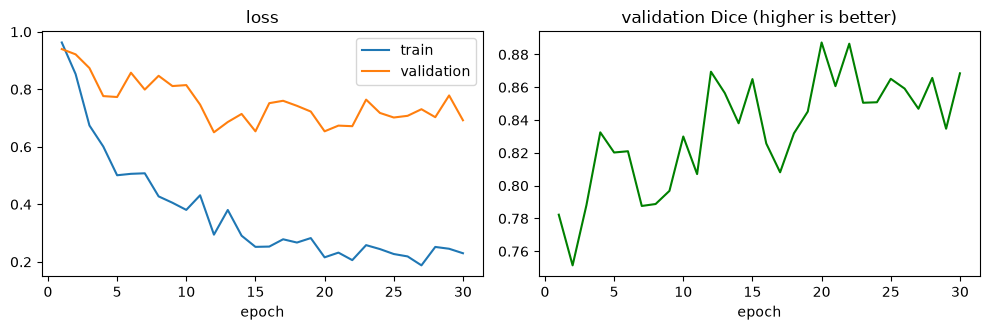

In [12]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="validation")
ax[0].set_xlabel("epoch"); ax[0].set_title("loss"); ax[0].legend()
ax[1].plot(h.epoch, h.val_dice, "g-"); ax[1].set_xlabel("epoch"); ax[1].set_title("validation Dice (higher is better)")
plt.tight_layout(); plt.show()

## 6. Inference: segmentation, NG percentage, defect dimensions

`segment_image` runs the whole chain on one image and returns the NG mask at the **original (processed) resolution**, so measurements are accurate.

**How dimensions are measured:** every connected NG region is analysed with OpenCV:
* `area`: number of NG pixels
* `length` x `width`: the sides of the smallest *rotated* rectangle around the region (so a diagonal scratch is measured along its own direction, not along the image axes)
* `feret`: the longest distance between any two points of the region (maximum caliper diameter)

**Pixels -> millimetres** needs a scale. Set in the settings either `mm_per_pixel` (fixed camera, scale of the original image) or `plate_long_side_mm` (the real length of the plate's longer side; the scale is then derived for each image). Without either, sizes are reported in pixels.
The mm values assume the plate faces the camera squarely and that the mask contains the plate only (no hook), so check the outline in section 2.

In [13]:
@torch.no_grad()
def predict_prob(model, crop_img, crop_obj):
    x = torch.from_numpy(to_input(crop_img, crop_obj)).unsqueeze(0).to(DEVICE)
    return torch.sigmoid(model(x))[0, 0].cpu().numpy()

In [14]:
def remove_small_blobs(mask, min_area):
    if min_area <= 1:
        return mask
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    keep = np.zeros(n, bool)
    keep[1:] = stats[1:, cv2.CC_STAT_AREA] >= min_area
    return keep[lab].astype(np.uint8)

def mm_per_pixel(obj, scale):
    # millimetres per (processed) pixel, or None if no calibration is configured
    if CFG.mm_per_pixel:
        return float(CFG.mm_per_pixel) * scale
    if CFG.plate_long_side_mm:
        cnts, _ = cv2.findContours(obj, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        (_, _), (w, h), _ = cv2.minAreaRect(max(cnts, key=cv2.contourArea))
        return float(CFG.plate_long_side_mm) / max(w, h)
    return None

def measure_defects(defect, prob, obj_area, mmpp):
    # one row per connected NG region, largest first. Lengths are in pixels (+ mm when mmpp is given).
    n, lab, stats, _ = cv2.connectedComponentsWithStats(defect, connectivity=8)
    rows = []
    for k in range(1, n):
        x, y, w, h, area = (int(v) for v in stats[k])
        sub = lab[y:y + h, x:x + w] == k
        ys, xs = np.nonzero(sub)
        pts = np.column_stack([xs + x, ys + y]).astype(np.float32)
        hull = cv2.convexHull(pts).reshape(-1, 2)
        (cx, cy), (rw, rh), ang = cv2.minAreaRect(hull)
        feret = float(np.sqrt(((hull[:, None, :] - hull[None, :, :]) ** 2).sum(-1)).max()) + 1.0   # +1: count pixel extent, not centre-to-centre
        row = dict(area_px=area, pct_of_plate=100.0 * area / max(obj_area, 1),
                   length_px=max(rw, rh) + 1.0, width_px=min(rw, rh) + 1.0, feret_px=feret,
                   x=x, y=y, w=w, h=h, max_prob=float(prob[y:y + h, x:x + w][sub].max()),
                   _box=cv2.boxPoints(((cx, cy), (rw, rh), ang)))
        if mmpp:
            row.update(area_mm2=area * mmpp ** 2, length_mm=row["length_px"] * mmpp,
                       width_mm=row["width_px"] * mmpp, feret_mm=feret * mmpp)
        rows.append(row)
    rows.sort(key=lambda r: -r["area_px"])
    for i, r in enumerate(rows, 1):
        r["id"] = i
    return rows

def defects_table(res):
    cols = ["id", "area_mm2", "length_mm", "width_mm", "feret_mm", "area_px", "length_px", "width_px", "feret_px",
            "pct_of_plate", "max_prob", "x", "y", "w", "h"]
    df = pd.DataFrame([{k: v for k, v in d.items() if k != "_box"} for d in res["defects"]])
    return df[[c for c in cols if c in df.columns]].round(3) if len(df) else df

def decide(ng_percent):
    return "NG" if ng_percent >= CFG.ng_percent_thr else "OK"

def segment_image(path, model=None):
    # full pipeline on one image file -> dict with masks, defect list, NG % and verdict
    model = MODEL if model is None else model
    img, scale = load_rgb(path)
    obj = get_object_mask(path, img)
    ci, co, (x0, y0, x1, y1) = make_crop(img, obj)
    p = predict_prob(model, ci, co)                                              # probability map at network resolution
    prob = np.zeros(obj.shape, np.float32)
    prob[y0:y1, x0:x1] = cv2.resize(p, (x1 - x0, y1 - y0), interpolation=cv2.INTER_LINEAR)   # back to full resolution
    prob *= obj                                                                  # nothing outside the plate can be NG
    obj_area = int(obj.sum())
    defect = remove_small_blobs((prob >= CFG.pixel_thr).astype(np.uint8), CFG.min_defect_frac * obj_area)
    mmpp = mm_per_pixel(obj, scale)
    ng_percent = 100.0 * int(defect.sum()) / max(obj_area, 1)
    return dict(path=str(path), image=img, obj=obj, prob=prob, defect=defect, bbox=(x0, y0, x1, y1), scale=scale,
                mm_per_px=mmpp, obj_area=obj_area, ng_percent=ng_percent,
                defects=measure_defects(defect, prob, obj_area, mmpp))

In [15]:
def show_inspection(res, gt=None, save_path=None):
    # 3 panels: input + plate outline | good (green) / NG (red) segmentation with measurements | NG probability
    x0, y0, x1, y1 = res["bbox"]
    sl = (slice(y0, y1), slice(x0, x1))
    img, obj, dfc, prob = res["image"][sl], np.ascontiguousarray(res["obj"][sl]), res["defect"][sl], res["prob"][sl]
    unit = "mm" if res["mm_per_px"] else "px"

    fig, ax = plt.subplots(1, 3, figsize=(15, 5.2))
    ax[0].imshow(img)
    for c in cv2.findContours(obj, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]:
        c = c[:, 0, :]; ax[0].plot(c[:, 0], c[:, 1], "c-", lw=1.2)
    ax[0].set_title("input + plate outline")

    seg = np.zeros((*obj.shape, 4), np.float32)
    seg[obj > 0] = (0.0, 0.8, 0.0, 0.25)       # good region
    seg[dfc > 0] = (1.0, 0.0, 0.0, 0.65)       # NG region
    ax[1].imshow(img); ax[1].imshow(seg)
    for d in res["defects"]:
        pts = d["_box"] - np.array([x0, y0])
        ax[1].add_patch(Polygon(pts, closed=True, fill=False, ec="yellow", lw=1.5))
        ax[1].text(pts[:, 0].min(), pts[:, 1].min() - 4, f"#{d['id']}: {d[f'length_{unit}']:.1f} x {d[f'width_{unit}']:.1f} {unit}",
                   color="yellow", fontsize=8, backgroundcolor=(0, 0, 0, 0.55))
    ax[1].set_title("green = good, red = NG, yellow = measured box")

    ax[2].imshow(prob, cmap="jet", vmin=0, vmax=1)
    if gt is not None:
        for c in cv2.findContours(np.ascontiguousarray(gt[sl]), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]:
            c = c[:, 0, :]; ax[2].plot(np.r_[c[:, 0], c[0, 0]], np.r_[c[:, 1], c[0, 1]], "w--", lw=1.2)
        ax[2].set_title("NG probability (white dashed = your mask)")
    else:
        ax[2].set_title("NG probability")
    for a in ax: a.axis("off")
    fig.suptitle(f"{Path(res['path']).name} | NG area {res['ng_percent']:.3f}% of plate | {len(res['defects'])} defect(s) | "
                 f"verdict: {decide(res['ng_percent'])}", fontsize=11)
    plt.tight_layout()
    if save_path is not None:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=110)
    plt.show()

def inspect_image(path, mask_path=None, save=True, model=None):
    # segment one image, print the verdict and the defect table, show the figure
    res = segment_image(path, model)
    gt = load_binary_mask(mask_path, res["image"].shape[:2]) if mask_path is not None else None
    unit = "mm" if res["mm_per_px"] else "px (set CFG.mm_per_pixel or CFG.plate_long_side_mm for mm)"
    print(f"{Path(path).name}: NG area = {res['ng_percent']:.3f}% of plate -> {decide(res['ng_percent'])} | sizes in {unit}")
    if res["defects"]:
        display(defects_table(res))
    show_inspection(res, gt, save_path=(CFG.out_dir / "inspections" / f"{Path(path).stem}.png") if save else None)
    return res

In [19]:
CFG.out_dir

PosixPath('/Users/sarathchintalapati/Desktop/TakeHomeAssisment/anomaly-detection/outputs/segmentation')

## 7. Evaluate on the test set

Pixel-level scores (Dice, IoU) tell you how well the painted regions match your masks. Image-level scores tell you how well the *NG %* rule separates good from bad plates.

In [16]:
test_items = collect_items("test", require_mask=False)
assert test_items, f"No test images found under {CFG.data_root / 'test'}"

rows, I_, P_, G_ = [], 0, 0, 0
for path, label, mp in tqdm(test_items, desc="testing"):
    res = segment_image(path)
    unit = "mm" if res["mm_per_px"] else "px"
    pred = res["defect"].astype(bool)
    row = dict(file=path.name, label=label, ng_percent=res["ng_percent"], n_defects=len(res["defects"]),
               pred_len=max([d[f"length_{unit}"] for d in res["defects"]], default=0.0))
    if label == 0 or mp is not None:                              # ground truth known (good images: no defect pixels)
        gt = load_binary_mask(mp, pred.shape).astype(bool) if mp is not None else np.zeros_like(pred)
        inter, ps, gs = int((pred & gt).sum()), int(pred.sum()), int(gt.sum())
        I_ += inter; P_ += ps; G_ += gs
        row.update(gt_area_px=gs, pred_area_px=ps,
                   dice=2 * inter / (ps + gs) if ps + gs else np.nan,
                   iou=inter / (ps + gs - inter) if ps + gs - inter else np.nan)
        if gs:
            gtd = measure_defects(gt.astype(np.uint8), gt.astype(np.float32), res["obj_area"], res["mm_per_px"])
            row["gt_len"] = max(d[f"length_{unit}"] for d in gtd)
    rows.append(row)

test_df = pd.DataFrame(rows)
LEN_UNIT = "mm" if CFG.mm_per_pixel or CFG.plate_long_side_mm else "px"
print(f"{len(test_df)} test images: {(test_df.label == 0).sum()} good, {(test_df.label == 1).sum()} bad")
if G_ + P_ > 0:
    print(f"pooled pixel metrics -> Dice {2 * I_ / (P_ + G_):.3f} | IoU {I_ / max(P_ + G_ - I_, 1):.3f}   (all test pixels inside the plates)")
display(test_df.round(3))

testing: 100%|██████████| 26/26 [00:09<00:00,  2.66it/s]

26 test images: 26 good, 0 bad
pooled pixel metrics -> Dice 0.000 | IoU 0.000   (all test pixels inside the plates)


,file,label,ng_percent,n_defects,pred_len,gt_area_px,pred_area_px,dice,iou
0,000.png,0,0.000,0,0.0,0,0,NaN,NaN
1,001.png,0,0.000,0,0.0,0,0,NaN,NaN
2,002.png,0,0.000,0,0.0,0,0,NaN,NaN
3,003.png,0,0.000,0,0.0,0,0,NaN,NaN
4,004.png,0,0.000,0,0.0,0,0,NaN,NaN
5,005.png,0,0.000,0,0.0,0,0,NaN,NaN
6,006.png,0,0.000,0,0.0,0,0,NaN,NaN
7,007.png,0,0.000,0,0.0,0,0,NaN,NaN
8,008.png,0,0.000,0,0.0,0,0,NaN,NaN
9,009.png,0,0.000,0,0.0,0,0,NaN,NaN


In [20]:
# ---- image-level: how well does "NG %" separate good from bad? ----
y, s = test_df.label.values, test_df.ng_percent.values
if len(set(y)) == 2:
    auc = roc_auc_score(y, s)
    prec, rec, thr = precision_recall_curve(y, s)
    f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    best_thr = float(thr[int(np.argmax(f1s))])
    print(f"ROC-AUC of NG %: {auc:.4f}")
    print(f"best-F1 cut-off on this test set: {best_thr:.3f} %  (optimistic, it is tuned on the same images)")
    print(f"\ncut-off in use (CFG.ng_percent_thr) = {CFG.ng_percent_thr} %")
    pred = (s >= CFG.ng_percent_thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    print(f"precision {precision_score(y, pred, zero_division=0):.3f} | recall {recall_score(y, pred, zero_division=0):.3f} | "
          f"F1 {f1_score(y, pred, zero_division=0):.3f} | TN={tn} FP={fp} FN={fn} TP={tp}")
    wrong = test_df[pred != y]
    if len(wrong):
        print("\nmisclassified images:"); display(wrong[["file", "label", "ng_percent", "n_defects"]].round(3))

    fpr, tpr, _ = roc_curve(y, s)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
    ax[0].plot(fpr, tpr, label=f"AUC={auc:.3f}"); ax[0].plot([0, 1], [0, 1], "--", c="gray")
    ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate"); ax[0].legend(); ax[0].set_title("ROC")
    bins = np.logspace(-3, 2, 30)
    ax[1].hist(np.clip(s[y == 0], 1e-3, None), bins=bins, alpha=0.7, label="good")
    ax[1].hist(np.clip(s[y == 1], 1e-3, None), bins=bins, alpha=0.7, label="bad")
    ax[1].axvline(CFG.ng_percent_thr, c="k", ls="--", label="cut-off"); ax[1].set_xscale("log")
    ax[1].set_xlabel("NG area as % of plate (log scale; zeros plotted at 0.001)"); ax[1].legend(); ax[1].set_title("NG % distribution")
    plt.tight_layout(); plt.show()
else:
    print("Need both good and bad test images for image-level metrics.")

# ---- dimension accuracy on bad images that have a mask ----
dim = test_df.dropna(subset=["gt_len"]) if "gt_len" in test_df else pd.DataFrame()
if len(dim):
    dim = dim.assign(error=dim.pred_len - dim.gt_len, error_pct=100 * (dim.pred_len - dim.gt_len) / dim.gt_len)
    print(f"\nlargest-defect length, predicted vs your mask ({LEN_UNIT}):")
    display(dim[["file", "gt_len", "pred_len", "error", "error_pct"]].round(2))
    print(f"mean absolute error: {dim.error.abs().mean():.2f} {LEN_UNIT} ({dim.error_pct.abs().mean():.1f} %)")

Need both good and bad test images for image-level metrics.


### Choosing the NG % cut-off

Look at the histogram: good plates should sit far to the left (about 0 %), bad plates further right. Pick a cut-off in the gap, then set `CFG.ng_percent_thr` and rerun the evaluation cell to see the effect.
* Many false alarms on good plates -> raise the cut-off (or raise `min_defect_frac` / `pixel_thr` to suppress noise).
* Defects missed -> lower it (or lower `pixel_thr`).

Because only a few defect images exist, treat the best-F1 value as a hint, and prefer a cut-off with some margin on both sides.

## 8. Look at results

000.png: NG area = 0.000% of plate -> OK | sizes in px (set CFG.mm_per_pixel or CFG.plate_long_side_mm for mm)


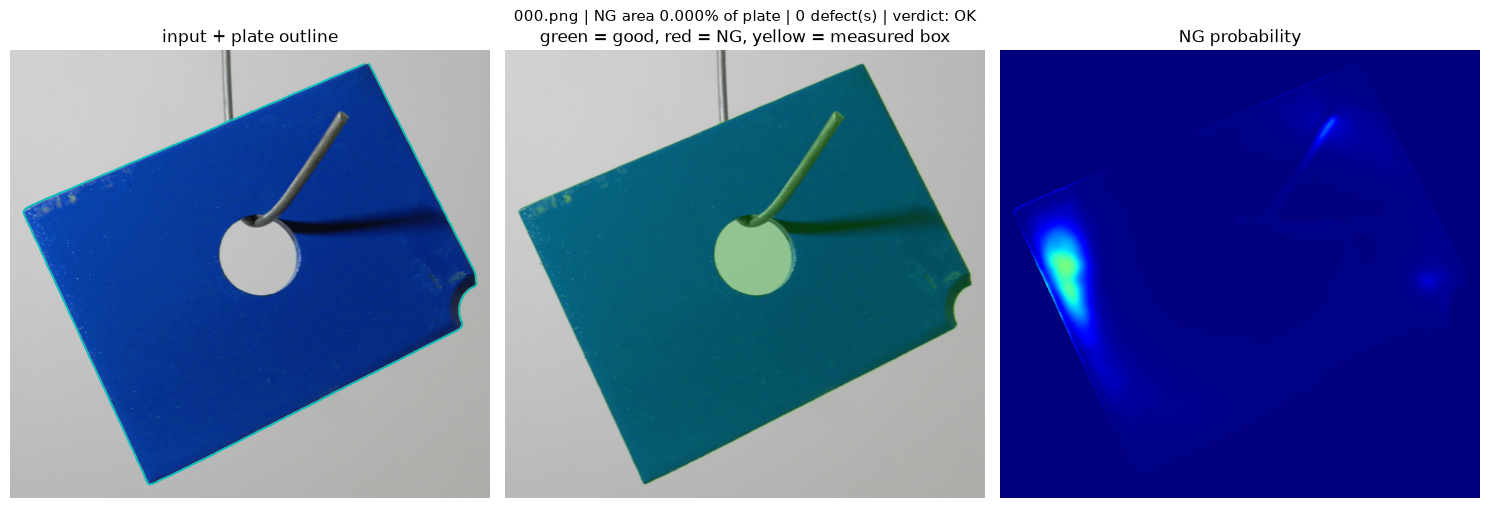

001.png: NG area = 0.000% of plate -> OK | sizes in px (set CFG.mm_per_pixel or CFG.plate_long_side_mm for mm)


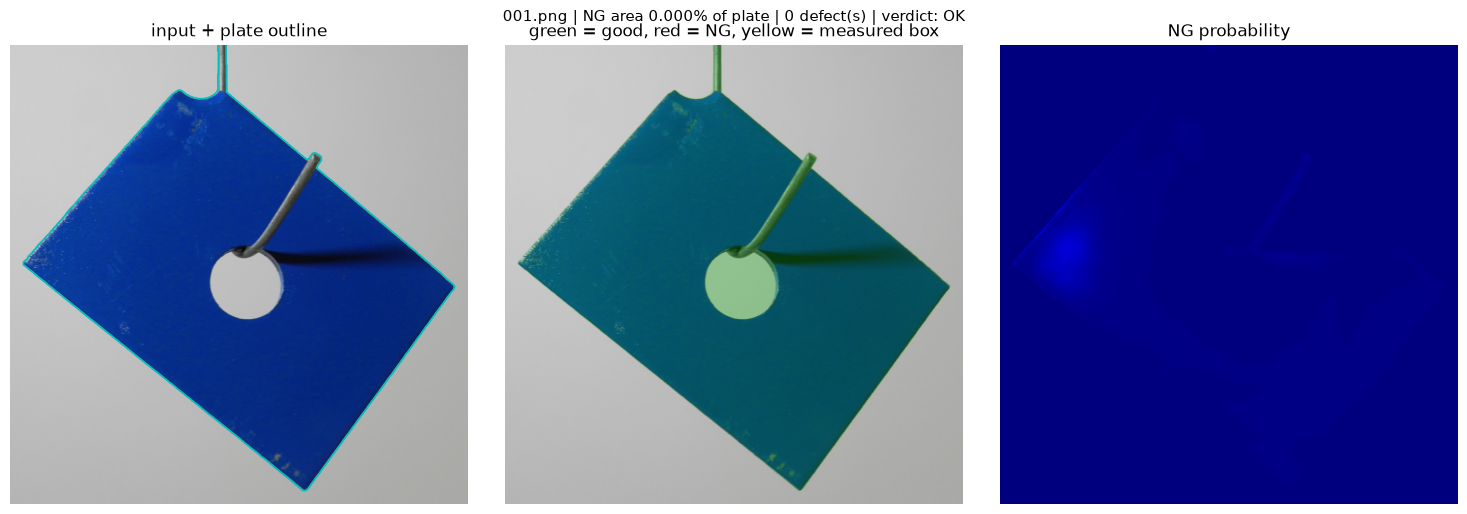

In [21]:
# bad test images first (with your mask overlaid when available), then a couple of good ones
bad = [(p, mp) for p, lab, mp in test_items if lab == 1][:4]
good = [(p, None) for p, lab, _ in test_items if lab == 0][:2]
for p, mp in bad + good:
    inspect_image(p, mp, save=True)

## 9. Inspect new images

Use `inspect_image(path)` for one image or `inspect_folder(folder)` for a whole folder. The latter writes two CSV files to `outputs/segmentation/`: a per-image summary (verdict, NG %) and a per-defect table (dimensions).

In a **new session** you don't need to retrain. Run the cells from section 1 up to and including section 6 (skip data preparation, training and evaluation), then run `MODEL = load_model(CFG.model_path)`.

In [22]:
def inspect_folder(folder, show=False, model=None):
    summary, defects = [], []
    for p in tqdm(list_images(folder), desc="inspecting"):
        res = segment_image(p, model)
        summary.append(dict(file=Path(p).name, verdict=decide(res["ng_percent"]), ng_percent=round(res["ng_percent"], 4),
                            n_defects=len(res["defects"])))
        for d in res["defects"]:
            defects.append(dict(file=Path(p).name, id=d["id"], **{k: (round(v, 3) if isinstance(v, float) else v) for k, v in d.items() if k not in ("_box", "id")}))
        if show:
            show_inspection(res, save_path=CFG.out_dir / "inspections" / f"{Path(p).stem}.png")
    summary_df, defects_df = pd.DataFrame(summary), pd.DataFrame(defects)
    CFG.out_dir.mkdir(parents=True, exist_ok=True)
    summary_df.to_csv(CFG.out_dir / "summary.csv", index=False)
    defects_df.to_csv(CFG.out_dir / "defects.csv", index=False)
    print(f"saved {CFG.out_dir / 'summary.csv'} and {CFG.out_dir / 'defects.csv'}")
    return summary_df, defects_df

# Examples (uncomment and point at your own files):
# inspect_image(ROOT / "data" / "seg" / "test" / "bad" / "some_image.png")
# summary_df, defects_df = inspect_folder(ROOT / "data" / "seg" / "test" / "bad")
# display(summary_df)